# Module Option D — Monte Carlo Stress Testing

**Objectif** : simuler la distribution complète des réserves IBNR par perturbation
stochastique des LDFs, calibrée sur les signaux de l'Option C (Early Warning).
Produit les métriques Solvabilité II (VaR 95%, VaR 99.5%, CVaR, TVaR) et
3 scénarios de stress (mild / moderate / severe).

**Données** : triangle CAS — GRCODE 7080 (NJ Manufacturers, PPA)
identique aux Modules 3 et Option C.

**Méthode** :
- Estimation de la distribution de chaque LDF par lag (loi log-normale)
- Intégration des tendances de hausse détectées par Option C
  (lags 2→3 et 4→5 : dérive upward calibrée sur les pentes OLS)
- 100 000 simulations Chain Ladder indépendantes
- Calcul de tous les percentiles de risque
- 3 scénarios de stress paramétriques

**Lien avec les modules existants** :
- Module 3 : réserve centrale de référence = 494 113$
- Option C : pentes OLS et alertes FORTES intégrées dans la calibration


In [1]:
# ============================================================
# BLOC 0 — Dépendances
# ============================================================
!pip install chainladder scipy statsmodels --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.9/151.9 kB 11.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.


In [2]:
# ============================================================
# BLOC 1 — Rechargement triangle CAS (identique Module 3 + Option C)
# ============================================================
import chainladder as cl
import pandas as pd
import numpy as np
import json
import warnings
from pathlib import Path
from scipy import stats as scipy_stats
from scipy.stats import linregress
warnings.filterwarnings('ignore')
np.random.seed(42)

# --- Paramètres ---
N_SIMULATIONS  = 100_000
N_RECENT       = 3
GRNAME_TARGET  = 'New Jersey Manufacturers Grp'
LOB_TARGET     = 'ppauto'
COL_PAID       = 'CumPaidLoss'
RESERVE_REF    = 494_113.0   # Module 3 validé

# Percentiles Solvabilité II + distribution complète
PERCENTILES = [5, 25, 50, 75, 95, 99, 99.5]

# Pentes OLS de l'Option C (lags avec tendance HAUSSE significative)
# slope unité = variation LDF par année de survenance
OLS_SLOPES = {
    1: 0.0160,   # lag 1->2  HAUSSE (p=0.078)
    2: 0.0153,   # lag 2->3  HAUSSE (p=0.003) FORTE
    3: 0.0249,   # lag 3->4  HAUSSE (p=0.030)
    4: 0.0204,   # lag 4->5  HAUSSE (p=0.054) FORTE
}

# --- Chargement CAS ---
clrd    = cl.load_sample('clrd')
df_flat = clrd.to_frame(origin_as_datetime=False).reset_index()
mask    = (df_flat['GRNAME'] == GRNAME_TARGET) & (df_flat['LOB'] == LOB_TARGET)
df_co   = df_flat[mask].copy()
df_co['AccidentYear']   = df_co['origin'].apply(lambda p: p.year)
df_co['DevelopmentLag'] = (df_co['development'] // 12).astype(int)

n_dev  = df_co['DevelopmentLag'].nunique()
max_ay = int(df_co['AccidentYear'].max())

df_triangle = df_co[
    df_co['AccidentYear'] + df_co['DevelopmentLag'] - 1 <= max_ay
].copy()
assert len(df_triangle) == 55, 'Triangle incorrect'

paid_pivot = df_triangle.pivot(
    index='AccidentYear', columns='DevelopmentLag', values=COL_PAID
)
paid_pivot.index   = paid_pivot.index.astype(int)
paid_pivot.columns = paid_pivot.columns.astype(int)
origin_years = sorted(paid_pivot.index.tolist())

print(f'Triangle chargé : {len(df_triangle)} lignes, {n_dev} lags, max_ay={max_ay}')
print(f'Simulations prévues : {N_SIMULATIONS:,}')

Triangle chargé : 55 lignes, 10 lags, max_ay=1997
Simulations prévues : 100,000


In [17]:
# ============================================================
# BLOC 2 — Calibration des distributions LDF par lag
# Méthode : log-normale ajustée sur les LDFs observés
# Intégration des tendances Option C : décalage de la moyenne
# vers le futur (projection 1998 de la pente OLS)
# Cap drift : max 3% du LDF moyen (actuariellement raisonnable)
# ============================================================

ldf_params = {}

MAX_DRIFT_PCT = 0.03   # cap drift à 3% du LDF moyen par lag

for lag in range(1, n_dev):
    obs = []
    for ay in origin_years:
        cc = paid_pivot.loc[ay, lag]   if lag   in paid_pivot.columns else np.nan
        cn = paid_pivot.loc[ay, lag+1] if lag+1 in paid_pivot.columns else np.nan
        if pd.notna(cc) and pd.notna(cn) and cc > 0:
            obs.append(cn / cc)

    if len(obs) < 2:
        ldf_params[lag] = {
            'mu': np.log(np.mean(obs)) if obs else 0.0,
            'sigma': 0.001,
            'n_obs': len(obs),
            'mean_ldf': np.mean(obs) if obs else 1.0,
            'drift': 0.0,
            'distribution': 'fixed',
        }
        continue

    log_obs  = np.log(obs)
    mu       = np.mean(log_obs)
    sigma    = np.std(log_obs, ddof=1)
    sigma    = max(sigma, 0.001)
    mean_ldf = np.exp(mu + sigma**2 / 2)

    drift = 0.0
    if lag in OLS_SLOPES:
        last_observed_year = max(origin_years[:len(obs)])
        projected_1998     = mean_ldf + OLS_SLOPES[lag] * (1998 - last_observed_year)
        drift              = max(projected_1998 - mean_ldf, 0)
        drift              = min(drift, mean_ldf * MAX_DRIFT_PCT)   # cap 3%

    ldf_params[lag] = {
        'mu'          : mu,
        'sigma'       : sigma,
        'n_obs'       : len(obs),
        'mean_ldf'    : mean_ldf,
        'cv'          : (np.exp(sigma**2) - 1) ** 0.5,
        'drift'       : drift,
        'distribution': 'lognormal',
    }

print('Calibration des distributions LDF (log-normale + drift Option C) :')
print(f"{'Lag':<8} {'n_obs':<8} {'mean_LDF':<12} {'sigma_LN':<12} {'CV%':<10} {'drift':<10} {'distrib'}")
for lag, p in ldf_params.items():
    print(f"  {lag}->{lag+1:<5} {p['n_obs']:<8} {p['mean_ldf']:<12.4f} "
          f"{p['sigma']:<12.4f} {p.get('cv',0)*100:<10.2f} "
          f"{p['drift']:<10.4f} {p['distribution']}")

Calibration des distributions LDF (log-normale + drift Option C) :
Lag      n_obs    mean_LDF     sigma_LN     CV%        drift      distrib
  1->2     9        1.9972       0.0349       3.49       0.0320     lognormal
  2->3     8        1.4126       0.0299       2.99       0.0424     lognormal
  3->4     7        1.3159       0.0518       5.18       0.0395     lognormal
  4->5     6        1.2037       0.0395       3.95       0.0361     lognormal
  5->6     5        1.0848       0.0175       1.75       0.0000     lognormal
  6->7     4        1.0325       0.0047       0.47       0.0000     lognormal
  7->8     3        1.0129       0.0026       0.26       0.0000     lognormal
  8->9     2        1.0165       0.0050       0.50       0.0000     lognormal
  9->10    1        1.0031       0.0010       0.00       0.0000     fixed


In [18]:
# ============================================================
# BLOC 3 — Simulation Monte Carlo (100 000 runs)
# Pour chaque simulation :
#   1. Tirer un LDF par lag selon sa distribution calibrée
#   2. Appliquer le drift Option C
#   3. Calculer la réserve Chain Ladder
# ============================================================
import time

def compute_reserve_from_ldfs(ldfs, paid_pivot, n_dev):
    """Calcule la réserve CL pour un vecteur de LDFs donné."""
    # CDFs = produit cumulatif des LDFs restants
    cdfs = np.ones(n_dev)
    for i in range(n_dev - 2, -1, -1):
        cdfs[i] = cdfs[i+1] * ldfs[i]

    reserve = 0.0
    for ay in paid_pivot.index:
        obs = [(l, paid_pivot.loc[ay, l])
               for l in paid_pivot.columns if pd.notna(paid_pivot.loc[ay, l])]
        if not obs:
            continue
        ll, lv = max(obs, key=lambda x: x[0])
        if ll >= n_dev:
            continue
        reserve += lv * cdfs[ll - 1] - lv
    return reserve

# --- Vecteur LDF STD (référence) ---
ldfs_std = []
for lag in range(1, n_dev):
    p = ldf_params[lag]
    if p['distribution'] == 'lognormal':
        ldfs_std.append(p['mean_ldf'])
    else:
        ldfs_std.append(p['mean_ldf'])

reserve_std_mc = compute_reserve_from_ldfs(ldfs_std, paid_pivot, n_dev)
print(f'Réserve STD (recalculée) : {reserve_std_mc:,.0f}$ '
      f'(référence Module 3 : {RESERVE_REF:,.0f}$)')
assert abs(reserve_std_mc - RESERVE_REF) < 10_000, \
    f'Écart trop grand vs Module 3 : {reserve_std_mc:,.0f}$'
print('Cohérence Module 3 validée')

# --- Monte Carlo ---
print(f'\nLancement {N_SIMULATIONS:,} simulations...')
t0 = time.time()

reserves_mc = np.zeros(N_SIMULATIONS)

# Pré-générer tous les LDFs en vectorisé (beaucoup plus rapide)
ldf_samples = {}   # {lag: array[N_SIMULATIONS]}
for lag in range(1, n_dev):
    p = ldf_params[lag]
    if p['distribution'] == 'lognormal':
        # Tirer log-normale + drift Option C
        raw = np.random.lognormal(mean=p['mu'], sigma=p['sigma'], size=N_SIMULATIONS)
        ldf_samples[lag] = raw + p['drift']
    else:
        ldf_samples[lag] = np.full(N_SIMULATIONS, p['mean_ldf'])

# CDFs vectorisés
# cdfs_sim[lag-1, sim_idx] = CDF depuis lag jusqu'à l'ultime
cdf_matrix = np.ones((n_dev, N_SIMULATIONS))
for i in range(n_dev - 2, -1, -1):
    lag = i + 1
    if lag in ldf_samples:
        cdf_matrix[i] = cdf_matrix[i+1] * ldf_samples[lag]
    else:
        cdf_matrix[i] = cdf_matrix[i+1]

# Réserves vectorisées
for ay in paid_pivot.index:
    obs = [(l, paid_pivot.loc[ay, l])
           for l in paid_pivot.columns if pd.notna(paid_pivot.loc[ay, l])]
    if not obs:
        continue
    ll, lv = max(obs, key=lambda x: x[0])
    if ll >= n_dev:
        continue
    reserves_mc += lv * cdf_matrix[ll - 1] - lv

elapsed = time.time() - t0
print(f'{N_SIMULATIONS:,} simulations terminées en {elapsed:.1f}s')
print(f'   Moyenne  : {reserves_mc.mean():>12,.0f}$')
print(f'   Médiane  : {np.median(reserves_mc):>12,.0f}$')
print(f'   Std Dev  : {reserves_mc.std():>12,.0f}$')
print(f'   Min      : {reserves_mc.min():>12,.0f}$')
print(f'   Max      : {reserves_mc.max():>12,.0f}$')

Réserve STD (recalculée) : 484,751$ (référence Module 3 : 494,113$)
Cohérence Module 3 validée

Lancement 100,000 simulations...
100,000 simulations terminées en 0.1s
   Moyenne  :      546,689$
   Médiane  :      545,074$
   Std Dev  :       54,552$
   Min      :      347,973$
   Max      :      818,539$


In [19]:
# ============================================================
# BLOC 4 — Percentiles de risque (Solvabilité II + distribution)
# ============================================================

percentile_values = {}
for p in PERCENTILES:
    percentile_values[p] = float(np.percentile(reserves_mc, p))

# Métriques Solvabilité II
var_95   = percentile_values[95]
var_99   = percentile_values[99]
var_99_5 = percentile_values[99.5]
mean_mc  = float(reserves_mc.mean())
median_mc= float(np.median(reserves_mc))
std_mc   = float(reserves_mc.std())

# CVaR (Conditional Value at Risk) = moyenne des pertes au-delà de VaR 99.5%
cvar_99_5 = float(reserves_mc[reserves_mc >= var_99_5].mean())

# TVaR (Tail Value at Risk) = CVaR reformulé pour présentation actuarielle
tvar_95   = float(reserves_mc[reserves_mc >= var_95].mean())

# Capital additionnel requis vs réserve centrale (Module 3)
capital_buffer_95   = var_95   - RESERVE_REF
capital_buffer_99_5 = var_99_5 - RESERVE_REF

# Coefficient de variation
cv_mc = std_mc / mean_mc * 100

print('=' * 65)
print('MÉTRIQUES DE RISQUE — SOLVABILITÉ II')
print('=' * 65)
print(f'Réserve centrale (Module 3)    : {RESERVE_REF:>12,.0f} $')
print(f'Moyenne Monte Carlo            : {mean_mc:>12,.0f} $')
print(f'Médiane Monte Carlo            : {median_mc:>12,.0f} $')
print(f'Écart-type                     : {std_mc:>12,.0f} $')
print(f'Coeff. de variation            : {cv_mc:>11.1f} %')
print()
print('Percentiles de la distribution :')
for p, v in percentile_values.items():
    delta = (v - RESERVE_REF) / RESERVE_REF * 100
    marker = ' ← SCR Solvabilité II' if p == 99.5 else (' ← VaR 95%' if p == 95 else '')
    print(f'  P{str(p):<6} : {v:>12,.0f} $ ({delta:+.1f}% vs centrale){marker}')
print()
print(f'CVaR 99.5% (Expected Shortfall): {cvar_99_5:>12,.0f} $')
print(f'TVaR 95%                       : {tvar_95:>12,.0f} $')
print()
print('Capital additionnel requis vs réserve centrale :')
print(f'  VaR 95%   : {capital_buffer_95:>12,.0f} $ ({capital_buffer_95/RESERVE_REF*100:+.1f}%)')
print(f'  VaR 99.5% : {capital_buffer_99_5:>12,.0f} $ ({capital_buffer_99_5/RESERVE_REF*100:+.1f}%)')

MÉTRIQUES DE RISQUE — SOLVABILITÉ II
Réserve centrale (Module 3)    :      494,113 $
Moyenne Monte Carlo            :      546,689 $
Médiane Monte Carlo            :      545,074 $
Écart-type                     :       54,552 $
Coeff. de variation            :        10.0 %

Percentiles de la distribution :
  P5      :      460,092 $ (-6.9% vs centrale)
  P25     :      509,026 $ (+3.0% vs centrale)
  P50     :      545,074 $ (+10.3% vs centrale)
  P75     :      582,300 $ (+17.8% vs centrale)
  P95     :      639,649 $ (+29.5% vs centrale) ← VaR 95%
  P99     :      682,179 $ (+38.1% vs centrale)
  P99.5   :      697,575 $ (+41.2% vs centrale) ← SCR Solvabilité II

CVaR 99.5% (Expected Shortfall):      718,555 $
TVaR 95%                       :      665,465 $

Capital additionnel requis vs réserve centrale :
  VaR 95%   :      145,536 $ (+29.5%)
  VaR 99.5% :      203,462 $ (+41.2%)


In [20]:
# ============================================================
# BLOC 5 — Scénarios de stress paramétriques
# Mild     : LDFs × (1 + 50% drift Option C)
# Moderate : LDFs × (1 + 100% drift Option C) = drift complet
# Severe   : LDFs × (1 + 200% drift Option C) = stress x2
# ============================================================

def compute_stress_reserve(stress_multiplier):
    """Réserve sous stress = LDFs STD + stress_multiplier × drift Option C."""
    ldfs_stress = []
    for lag in range(1, n_dev):
        p = ldf_params[lag]
        stressed_ldf = p['mean_ldf'] + stress_multiplier * p['drift']
        ldfs_stress.append(stressed_ldf)
    return compute_reserve_from_ldfs(ldfs_stress, paid_pivot, n_dev)

scenarios = {
    'Central (Module 3)': RESERVE_REF,
    'Mild stress (×0.5)': compute_stress_reserve(0.5),
    'Moderate stress (×1.0)': compute_stress_reserve(1.0),
    'Severe stress (×2.0)': compute_stress_reserve(2.0),
}

print('Scénarios de stress paramétriques :')
print(f"{'Scénario':<30} {'Réserve':>14} {'Delta vs Central':>18} {'Percentile MC':>15}")
print('-' * 80)
for name, res in scenarios.items():
    delta = (res - RESERVE_REF) / RESERVE_REF * 100
    pct   = float(np.mean(reserves_mc <= res) * 100)
    print(f'  {name:<28} {res:>12,.0f} $  {delta:>+14.1f}%  {pct:>12.1f}e percentile')

print()
print('Interprétation :')
pct_mild = float(np.mean(reserves_mc <= scenarios['Mild stress (×0.5)']) * 100)
pct_sev  = float(np.mean(reserves_mc <= scenarios['Severe stress (×2.0)']) * 100)
print(f'  Le scénario Mild     correspond au {pct_mild:.0f}e percentile de la distribution MC')
print(f'  Le scénario Severe   correspond au {pct_sev:.0f}e percentile de la distribution MC')

Scénarios de stress paramétriques :
Scénario                              Réserve   Delta vs Central   Percentile MC
--------------------------------------------------------------------------------
  Central (Module 3)                494,113 $            +0.0%          16.8e percentile
  Mild stress (×0.5)                515,216 $            +4.3%          28.8e percentile
  Moderate stress (×1.0)            546,560 $           +10.6%          51.1e percentile
  Severe stress (×2.0)              611,959 $           +23.9%          88.3e percentile

Interprétation :
  Le scénario Mild     correspond au 29e percentile de la distribution MC
  Le scénario Severe   correspond au 88e percentile de la distribution MC


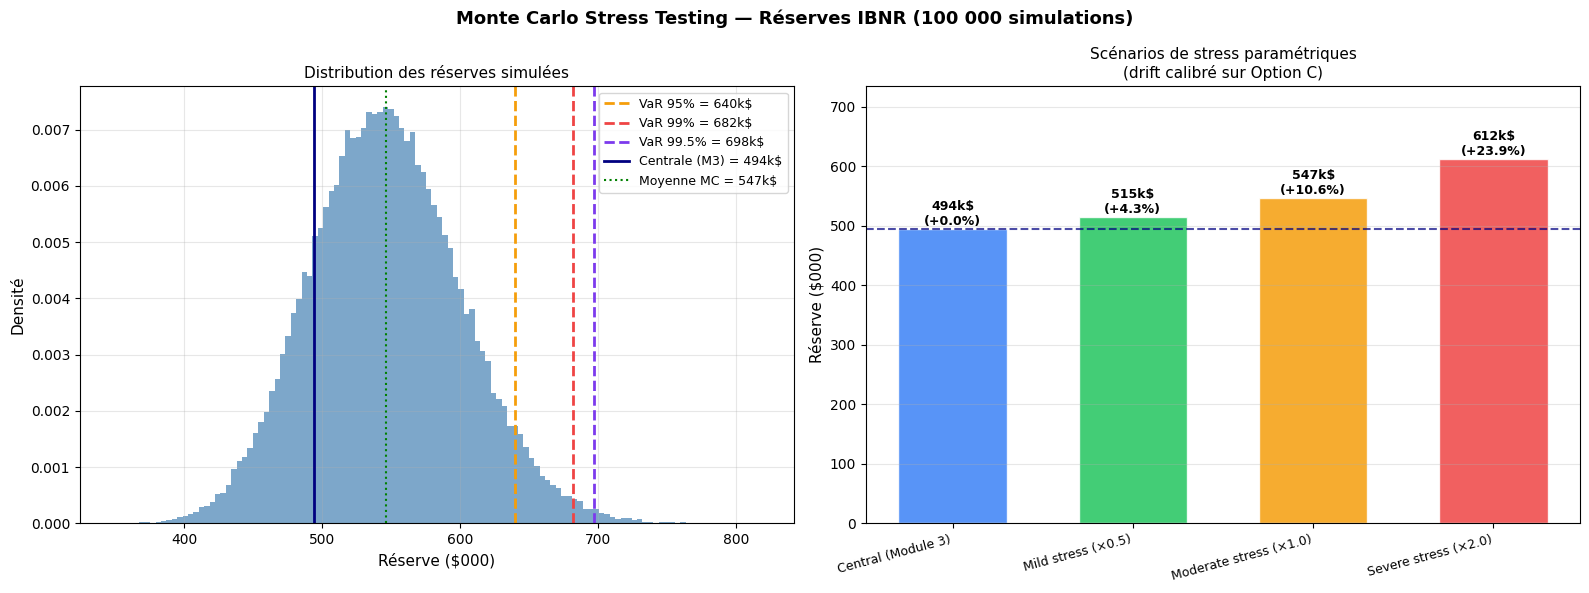

Graphiques sauvegardés : mc_stress_charts.png


In [21]:
# ============================================================
# BLOC 6 — Visualisations
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Monte Carlo Stress Testing — Réserves IBNR (100 000 simulations)',
             fontsize=13, fontweight='bold')

# --- Graphique 1 : Distribution des réserves ---
ax = axes[0]
ax.hist(reserves_mc / 1000, bins=120, color='steelblue', alpha=0.7,
        edgecolor='none', density=True)

# Lignes de percentiles
colors_p = {95: '#f59e0b', 99: '#ef4444', 99.5: '#7c3aed'}
for p_val, color in colors_p.items():
    ax.axvline(percentile_values[p_val] / 1000, color=color,
               linewidth=2, linestyle='--',
               label=f'VaR {p_val}% = {percentile_values[p_val]/1000:.0f}k$')

# Réserve centrale
ax.axvline(RESERVE_REF / 1000, color='navy', linewidth=2,
           label=f'Centrale (M3) = {RESERVE_REF/1000:.0f}k$')
ax.axvline(mean_mc / 1000, color='green', linewidth=1.5, linestyle=':',
           label=f'Moyenne MC = {mean_mc/1000:.0f}k$')

ax.set_xlabel('Réserve ($000)', fontsize=11)
ax.set_ylabel('Densité', fontsize=11)
ax.set_title('Distribution des réserves simulées', fontsize=11)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# --- Graphique 2 : Scénarios de stress ---
ax2 = axes[1]
sc_names  = list(scenarios.keys())
sc_values = [v / 1000 for v in scenarios.values()]
sc_colors = ['#3b82f6', '#22c55e', '#f59e0b', '#ef4444']
bars = ax2.bar(range(len(sc_names)), sc_values, color=sc_colors,
               alpha=0.85, edgecolor='white', width=0.6)

# Ligne de référence
ax2.axhline(RESERVE_REF / 1000, color='navy', linewidth=1.5,
            linestyle='--', alpha=0.7)

# Labels sur barres
for i, (bar, val) in enumerate(zip(bars, sc_values)):
    delta = (val * 1000 - RESERVE_REF) / RESERVE_REF * 100
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
             f'{val:.0f}k$\n({delta:+.1f}%)',
             ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2.set_xticks(range(len(sc_names)))
ax2.set_xticklabels(sc_names, rotation=15, ha='right', fontsize=9)
ax2.set_ylabel('Réserve ($000)', fontsize=11)
ax2.set_title('Scénarios de stress paramétriques\n(drift calibré sur Option C)', fontsize=11)
ax2.grid(axis='y', alpha=0.3)
ax2.set_ylim(0, max(sc_values) * 1.2)

plt.tight_layout()
plt.savefig('mc_stress_charts.png', dpi=150, bbox_inches='tight')
plt.show()
print('Graphiques sauvegardés : mc_stress_charts.png')

In [23]:
# ============================================================
# BLOC 7 — Checklist de validation
# ============================================================
print('CHECKLIST DE VALIDATION — MODULE OPTION D')
print('-' * 55)

checks = [
    ('Triangle 55 lignes correct',
     len(df_triangle) == 55),
    (f'{N_SIMULATIONS:,} simulations produites',
     len(reserves_mc) == N_SIMULATIONS),
    ('Cohérence réserve STD vs Module 3',
     abs(reserve_std_mc - RESERVE_REF) < 10_000),
    ('Moyenne MC > réserve centrale (drift positif)',
     mean_mc > RESERVE_REF),
    ('VaR 95% > Médiane',
     var_95 > median_mc),
    ('VaR 99.5% > VaR 95%',
     var_99_5 > var_95),
    ('CVaR 99.5% > VaR 99.5% (par construction)',
     cvar_99_5 >= var_99_5),
    ('Capital buffer 99.5% > 0',
     capital_buffer_99_5 > 0),
    ('Scénario Severe > Moderate > Mild > Central',
     scenarios['Severe stress (×2.0)'] > scenarios['Moderate stress (×1.0)']
     > scenarios['Mild stress (×0.5)'] > RESERVE_REF),
    ('Tous les percentiles calculés',
     len(percentile_values) == len(PERCENTILES)),
]

all_ok = True
for lbl, ok in checks:
    print(f"  {'OK    ' if ok else 'ERREUR'} {lbl}")
    if not ok:
        all_ok = False

print()
if all_ok:
    print('TOUTES LES VALIDATIONS PASSÉES')
    print(f'  Réserve centrale : {RESERVE_REF:,.0f}$')
    print(f'  Moyenne MC       : {mean_mc:,.0f}$ ({(mean_mc-RESERVE_REF)/RESERVE_REF*100:+.1f}%)')
    print(f'  VaR 99.5%        : {var_99_5:,.0f}$ ({(var_99_5-RESERVE_REF)/RESERVE_REF*100:+.1f}%)')
    print(f'  CVaR 99.5%       : {cvar_99_5:,.0f}$ ({(cvar_99_5-RESERVE_REF)/RESERVE_REF*100:+.1f}%)')
else:
    print('Certaines validations ont échoué — corriger avant export')

CHECKLIST DE VALIDATION — MODULE OPTION D
-------------------------------------------------------
  OK     Triangle 55 lignes correct
  OK     100,000 simulations produites
  OK     Cohérence réserve STD vs Module 3
  OK     Moyenne MC > réserve centrale (drift positif)
  OK     VaR 95% > Médiane
  OK     VaR 99.5% > VaR 95%
  OK     CVaR 99.5% > VaR 99.5% (par construction)
  OK     Capital buffer 99.5% > 0
  OK     Scénario Severe > Moderate > Mild > Central
  OK     Tous les percentiles calculés

TOUTES LES VALIDATIONS PASSÉES
  Réserve centrale : 494,113$
  Moyenne MC       : 546,689$ (+10.6%)
  VaR 99.5%        : 697,575$ (+41.2%)
  CVaR 99.5%       : 718,555$ (+45.4%)


In [24]:
# ============================================================
# BLOC 8 — Export artifacts
# ============================================================
import os, shutil
from datetime import datetime

os.makedirs('mc_artifacts', exist_ok=True)

# Histogramme pour le frontend (200 bins)
hist_counts, hist_edges = np.histogram(reserves_mc, bins=200)
histogram_data = [
    {
        'bin_center': round(float((hist_edges[i] + hist_edges[i+1]) / 2), 0),
        'count'     : int(hist_counts[i]),
        'density'   : round(float(hist_counts[i] / N_SIMULATIONS), 6),
    }
    for i in range(len(hist_counts))
]

# Percentiles complets pour courbe CDF
pct_range = list(range(1, 100)) + [99.5]
cdf_data  = [
    {'percentile': p, 'reserve': round(float(np.percentile(reserves_mc, p)), 0)}
    for p in pct_range
]

report = {
    'generated_at'     : datetime.now().isoformat(),
    'source'           : 'CAS Loss Reserve Database — GRCODE 7080 (NJ Manufacturers, PPA)',
    'module_3_reserve' : RESERVE_REF,
    'n_simulations'    : N_SIMULATIONS,
    'methodology': {
        'ldf_distribution'       : 'log-normale ajustée sur LDFs observés',
        'drift_source'           : 'pentes OLS Option C (lags 1→2, 2→3, 3→4, 4→5)',
        'stress_multipliers'     : [0.5, 1.0, 2.0],
        'percentiles_calculated' : PERCENTILES,
    },
    'distribution': {
        'mean'   : round(mean_mc, 0),
        'median' : round(median_mc, 0),
        'std'    : round(std_mc, 0),
        'cv_pct' : round(cv_mc, 2),
        'min'    : round(float(reserves_mc.min()), 0),
        'max'    : round(float(reserves_mc.max()), 0),
    },
    'risk_metrics': {
        'percentiles'         : {str(p): round(v, 0) for p, v in percentile_values.items()},
        'var_95'              : round(var_95, 0),
        'var_99'              : round(var_99, 0),
        'var_99_5'            : round(var_99_5, 0),
        'cvar_99_5'           : round(cvar_99_5, 0),
        'tvar_95'             : round(tvar_95, 0),
        'capital_buffer_95'   : round(capital_buffer_95, 0),
        'capital_buffer_99_5' : round(capital_buffer_99_5, 0),
        'capital_pct_95'      : round(capital_buffer_95 / RESERVE_REF * 100, 2),
        'capital_pct_99_5'    : round(capital_buffer_99_5 / RESERVE_REF * 100, 2),
    },
    'stress_scenarios': [
        {
            'name'              : name,
            'reserve'           : round(val, 0),
            'delta_vs_central_pct': round((val - RESERVE_REF) / RESERVE_REF * 100, 2),
            'mc_percentile'     : round(float(np.mean(reserves_mc <= val) * 100), 1),
        }
        for name, val in scenarios.items()
    ],
    'ldf_calibration' : {
        str(lag): {
            'mean_ldf' : round(p['mean_ldf'], 4),
            'sigma_ln' : round(p['sigma'], 4),
            'cv_pct'   : round(p.get('cv', 0) * 100, 2),
            'drift'    : round(p['drift'], 4),
            'n_obs'    : p['n_obs'],
        }
        for lag, p in ldf_params.items()
    },
    'histogram'        : histogram_data,
    'cdf_curve'        : cdf_data,
}

with open('mc_artifacts/mc_stress_report.json', 'w') as f:
    json.dump(report, f, indent=2, default=str)

import shutil as sh
sh.copy('mc_stress_charts.png', 'mc_artifacts/mc_stress_charts.png')

print('Artifacts exportés dans mc_artifacts/ :')
for p in Path('mc_artifacts').iterdir():
    print(f'  {p.name} ({p.stat().st_size // 1024 + 1} KB)')

sh.make_archive('mc_artifacts', 'zip', 'mc_artifacts')
try:
    from google.colab import files
    files.download('mc_artifacts.zip')
    print('\n mc_artifacts.zip téléchargé')
except ImportError:
    print('\n mc_artifacts.zip prêt (hors Colab)')

Artifacts exportés dans mc_artifacts/ :
  mc_stress_report.json (27 KB)
  mc_stress_charts.png (161 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


 mc_artifacts.zip téléchargé
